# Laboratorium 4 — Obsługa długich sekwencji: LSTM, GRU, splot 1D

**Cel:** pokazać, że prosty RNN nie radzi sobie z zależnościami długozasięgowymi,
a LSTM, GRU i rozszerzony (dilated) Conv1D — tak. Benchmark: klasyczny **adding problem**.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 1. Instalacja i import

In [1]:
!pip -q install torch numpy matplotlib

^C


In [66]:
import time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt

torch.manual_seed(0)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'; print('Urządzenie:', DEVICE)

Urządzenie: cuda


## 2. Dane: adding problem

In [67]:
np.random.seed(0)

def gen(N, L):
    val = np.random.rand(N, L, 1).astype(np.float32)
    mark = np.zeros((N, L, 1), np.float32)
    y = np.zeros((N, 1), np.float32)
    for i in range(N):
        p = np.random.choice(range(8,L), 2, replace=False)
        mark[i, p, 0] = 1.0
        y[i, 0] = val[i, p-8, 0].sum()
    x = np.concatenate([val, mark], axis=2)
    return torch.tensor(x).to(DEVICE), torch.tensor(y).to(DEVICE)

# Podgląd jednego przykładu
xx, yy = gen(1, 20)
poz = np.where(xx[0,:,1].cpu().numpy()==1)[0]
print('Oznaczone pozycje:', poz)
print('Wartości tam:', xx[0,poz,0].cpu().numpy().round(3))
print('Wskazywane pozycje:', poz-8)
print(f'Wartości na wskazanych pozycjach: {xx[0,poz-8,0].cpu().numpy().round(3)}')
print(f'Suma (cel): {float(yy[0,0]):.3f}\n')

Oznaczone pozycje: [12 17]
Wartości tam: [0.568 0.833]
Wskazywane pozycje: [4 9]
Wartości na wskazanych pozycjach: [0.424 0.383]
Suma (cel): 0.807



## 3. Modele

In [68]:
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=32):
        super().__init__()
        self.rnn={'RNN':nn.RNN,'LSTM':nn.LSTM,'GRU':nn.GRU}[typ](2,hidden,batch_first=True)
        self.fc=nn.Linear(hidden,1)
    def forward(self,x):
        out,_=self.rnn(x); return self.fc(out[:,-1,:])

class ConvNet(nn.Module):
    def __init__(self, ch=64, dilations=[1, 2, 4]):
        super().__init__()
        layers=[]
        in_ch=2
        for d in dilations:
            layers.append(nn.Conv1d(in_ch,ch,kernel_size=3,padding=d,dilation=d))
            layers.append(nn.ReLU())
            in_ch=ch
        self.net=nn.Sequential(*layers)
        self.fc=nn.Linear(ch,1)
    def forward(self,x):
        h=self.net(x.transpose(1,2)).mean(dim=2); return self.fc(h)

def licz_parametry(m): return sum(p.numel() for p in m.parameters())

## 4. Uczenie i ewaluacja

In [69]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, batch=128, lr=5e-3):
    model=model.to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=lr); Lf=nn.MSELoss()
    N=len(Xtr)
    t0=time.time()
    for ep in range(epoki):
        model.train(); perm=torch.randperm(N)
        for i in range(0,N,batch):
            idx=perm[i:i+batch]; opt.zero_grad()
            Lf(model(Xtr[idx]),Ytr[idx]).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
    czas=time.time()-t0
    model.eval()
    with torch.no_grad(): mse=Lf(model(Xte),Yte).item()
    return mse, czas, model

## 5. Porównanie architektur

In [70]:
wyniki = {}
for L in [50, 100]:
    print(f"\nTrening dla długości L = {L}")
    Xtr, Ytr = gen(4000, L)
    Xte, Yte = gen(800, L)
    srednia_treningu = Ytr.mean()
    baseline_mse = torch.mean((Yte - srednia_treningu)**2).item()
    print(f"Baseline (stała predykcja) MSE: {baseline_mse:.4f}")

    modele = {'SimpleRNN': RNNNet('RNN', hidden=32), 'LSTM': RNNNet('LSTM', hidden=32),
              'GRU': RNNNet('GRU', hidden=32), 'Conv1D_d124': ConvNet(dilations=[1, 2, 4])}

    if L == 100:
        modele['SimpleRNN_h64'] = RNNNet('RNN', hidden=64)
        modele['Conv1D_d111'] = ConvNet(dilations=[1, 1, 1])
    wyniki[L] = {'baseline': baseline_mse}

    for nazwa, m in modele.items():
        mse, czas, wytrenowany_model = trenuj(m, Xtr, Ytr, Xte, Yte, epoki=30, batch=128)
        wyniki[L][nazwa] = {'mse': mse, 'czas': czas, 'params': licz_parametry(m)}
        print(f'{nazwa:15s} MSE={mse:.4f}  czas={czas:4.1f}s  params={licz_parametry(m)}')

#przykład testowy z dużym błędem
        if L == 100 and nazwa == 'SimpleRNN':
            with torch.no_grad():
                pred = wytrenowany_model(Xte)
                bledy = (pred - Yte)**2
                idx_max_err = torch.argmax(bledy).item()
                poz_err = np.where(Xte[idx_max_err, :, 1].cpu().numpy() == 1)[0]
                prawidlowa_suma = Yte[idx_max_err].item()
                predykcja = pred[idx_max_err].item()
                print(f"Przykład testowy z dużym błędem dla SimpleRNN: znacznik w krokach {poz_err+1}, "
                      f"wskazywane wartości {Xte[idx_max_err, poz_err-8, 0].cpu().numpy().round(3)}, "
                      f"cel: {prawidlowa_suma:.3f}, pred: {predykcja:.3f}")


Trening dla długości L = 50
Baseline (stała predykcja) MSE: 0.1598
SimpleRNN       MSE=0.1598  czas= 2.3s  params=1185
LSTM            MSE=0.1597  czas= 2.5s  params=4641
GRU             MSE=0.1439  czas= 2.4s  params=3489
Conv1D_d124     MSE=0.1558  czas= 2.7s  params=25217

Trening dla długości L = 100
Baseline (stała predykcja) MSE: 0.1667
SimpleRNN       MSE=0.1703  czas= 2.5s  params=1185
Przykład testowy z dużym błędem dla SimpleRNN: znacznik w krokach [10 66], wskazywane wartości [0.975 0.986], cel: 1.961, pred: 0.942
LSTM            MSE=0.1667  czas= 2.6s  params=4641
GRU             MSE=0.1663  czas= 2.5s  params=3489
Conv1D_d124     MSE=0.1643  czas= 2.5s  params=25217
SimpleRNN_h64   MSE=0.5095  czas= 2.6s  params=4417
Conv1D_d111     MSE=0.1641  czas= 2.7s  params=25217


## 6. Wykres porównawczy

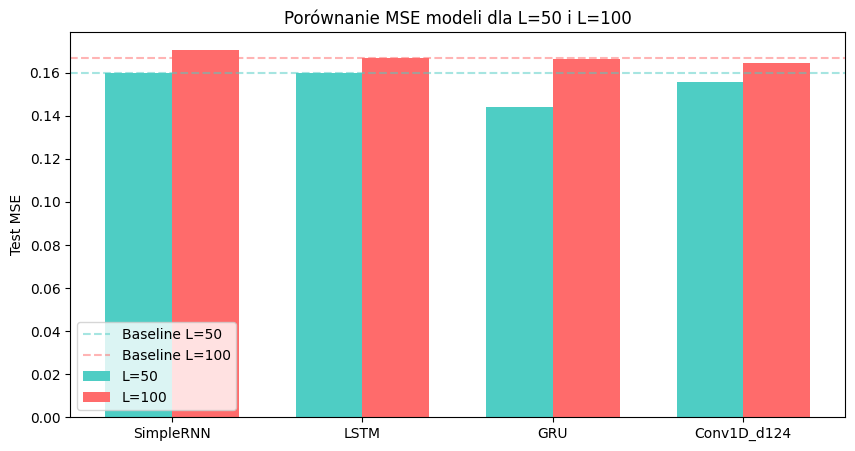

In [71]:
nazwy = ['SimpleRNN', 'LSTM', 'GRU', 'Conv1D_d124']
mse_L50 = [wyniki[50][m]['mse'] for m in nazwy]
mse_L100 = [wyniki[100][m]['mse'] for m in nazwy]
x = np.arange(len(nazwy))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, mse_L50, width, label='L=50', color='#4ecdc4')
rects2 = ax.bar(x + width/2, mse_L100, width, label='L=100', color='#ff6b6b')
ax.axhline(wyniki[50]['baseline'], ls='--', color='#4ecdc4', alpha=0.5, label='Baseline L=50')
ax.axhline(wyniki[100]['baseline'], ls='--', color='#ff6b6b', alpha=0.5, label='Baseline L=100')
ax.set_ylabel('Test MSE'); ax.set_title('Porównanie MSE modeli dla L=50 i L=100')
ax.set_xticks(x); ax.set_xticklabels(nazwy); ax.legend(); plt.show()